# 01 · Data exploration

What the processed Retrosheet dataset contains, and the patterns that shaped the modeling choices.

Needs `data/processed/` (`make build`). Outcomes from the test seasons (2024–2025) are never read here: tables with outcomes are loaded with a split filter for `train` and `validation` only.

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run from the repository root so the relative paths in configs/ and the manifest resolve.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("src").resolve()))
pd.set_option("display.width", 120, "display.max_columns", 20, "display.precision", 4)

## Coverage and splits

In [2]:
manifest = json.loads(Path("data/processed/manifest.json").read_text())
rows = pd.DataFrame(manifest["rows"]["games"], index=["games"]).T.join(
    pd.DataFrame(manifest["rows"]["states"], index=["event states"]).T)
rows.loc[["warmup", "train", "validation", "test"]]

,games,event states
warmup,4859,NaN
train,15473,1207905.0
validation,2430,190416.0
test,4859,378248.0


Warm-up seasons (2014–2015) only feed prior-season reliever ratings. Train is 2016–2022, validation 2023, test 2024–2025.

## From relief appearances to decision points

In [3]:
funnel = pd.Series(manifest["decision_funnel"], name="rows")
funnel.to_frame().assign(share_of_previous=lambda d: (d["rows"] / d["rows"].shift()).round(3))

,rows,share_of_previous
relief_appearances,150307,NaN
innings_7_9,105758,0.704
nine_inning_no_tie,105383,0.996
close_margin,64971,0.617
eligible_decisions,64426,0.992


## Run scoring by season

Share of relief-pitcher states after which the batting team scores again in the half-inning (target Y1). 2023 is the first season under the pitch clock, shift limits and larger bases.

,mean,size
season,,
2016,0.2598,70281
2017,0.2645,73029
2018,0.2651,77460
2019,0.2766,81778
2020,0.2784,30982
2021,0.2712,81073
2022,0.2619,78150
2023,0.2744,80901


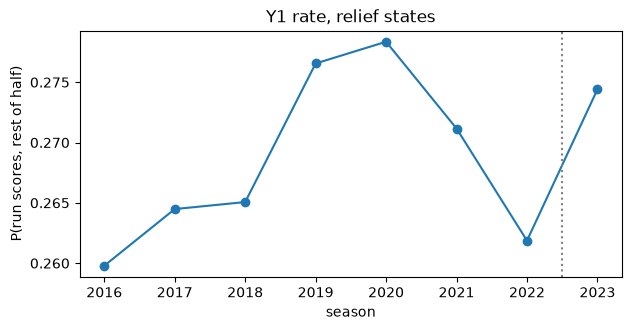

In [4]:
OUTCOME_SPLITS = [("split", "in", ["train", "validation"])]
states = pd.read_parquet("data/processed/states.parquet", filters=OUTCOME_SPLITS,
                         columns=["season", "split", "pitcher_is_starter", "scored_rest_half", "runs_rest_half",
                                  "inning", "state24", "pitcher_runs_saved_per100"])
relief = states[states["pitcher_is_starter"] == 0]
by_season = relief.groupby("season")["scored_rest_half"].agg(["mean", "size"])
ax = by_season["mean"].plot(marker="o", figsize=(7, 3.2), title="Y1 rate, relief states")
ax.axvline(2022.5, ls=":", c="grey"); ax.set_ylabel("P(run scores, rest of half)")
by_season

Scoring moves from season to season (2019–2020 were also high). A model trained on 2016–2022 predicts the pooled training level (26.75%), so it under-predicts 2023 (27.44%); that is the drift later corrected with an intercept recalibration fitted on 2023.

## Run-expectancy matrix (training seasons)

In [5]:
re = pd.read_csv("data/processed/re_matrix.csv", index_col=0)["expected_runs"]
re.index = pd.MultiIndex.from_tuples([(int(k[0]), k[2:]) for k in re.index], names=["outs", "bases (1B 2B 3B)"])
re.unstack("outs").round(3)

outs,0,1,2
bases (1B 2B 3B),,,
000,0.515,0.275,0.106
001,1.380,0.985,0.384
010,1.155,0.708,0.328
011,2.038,1.431,0.581
100,0.912,0.539,0.229
101,1.774,1.213,0.510
110,1.519,0.955,0.451
111,2.356,1.628,0.796


## Reliever ratings at decision points

Ratings are run prevention per batter faced, shrunk toward league average and computed from games before the decision date only. Positive = runs saved per 100 batters faced.

,best_runs_saved_per100,alt_runs_saved_per100,rating_gap_per100,n_available
count,50496.000,50496.000,50496.000,50496.000
mean,1.947,1.159,0.789,9.207
std,0.910,0.734,0.671,2.656
min,-1.400,-2.609,0.000,2.000
25%,1.319,0.652,0.257,7.000
50%,1.900,1.152,0.612,9.000
75%,2.504,1.648,1.169,11.000
max,5.543,3.937,5.031,21.000


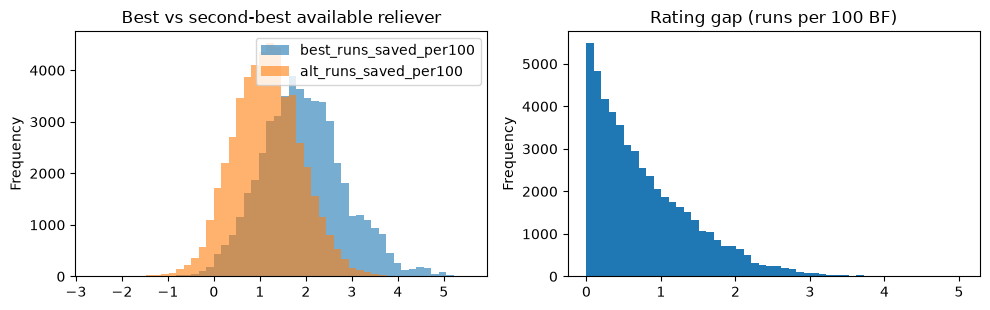

In [6]:
dec = pd.read_parquet("data/processed/decisions.parquet", filters=OUTCOME_SPLITS)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
dec[["best_runs_saved_per100", "alt_runs_saved_per100"]].plot.hist(bins=50, alpha=0.6, ax=axes[0])
axes[0].set_title("Best vs second-best available reliever")
dec["rating_gap_per100"].plot.hist(bins=50, ax=axes[1], title="Rating gap (runs per 100 BF)")
plt.tight_layout()
dec[["best_runs_saved_per100", "alt_runs_saved_per100", "rating_gap_per100", "n_available"]].describe().round(3)

## Who managers actually used

`actual_choice` places the reliever who entered within the rule-based ranking of available relievers. `rule_unavailable` is the availability rule's miss rate.

In [7]:
pd.crosstab(dec["entry_inning"], dec["actual_choice"], normalize="index").round(3)

actual_choice,best,second,other_available,rule_unavailable
entry_inning,,,,
7,0.108,0.162,0.705,0.025
8,0.184,0.209,0.572,0.035
9,0.438,0.179,0.325,0.058


Managers used the top-rated available reliever in about one decision point in four, and choices shift toward the best reliever in the 9th. The descriptive win rates by choice are confounded by why the manager chose, which is why the strategy comparison uses simulation rather than these raw differences.